<a href="https://www.kaggle.com/code/mukituislamnishat/brain-tumor-mri-classification-cnn?scriptVersionId=367001469" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
import os
import tensorflow as tf

base_dir = None
for root, dirs, files in os.walk('/kaggle/input'):
    dirs_lower = [d.lower() for d in dirs]
    if 'training' in dirs_lower and 'testing' in dirs_lower:
        base_dir = root
        train_folder = dirs[dirs_lower.index('training')]
        test_folder = dirs[dirs_lower.index('testing')]
        break

train_path = os.path.join(base_dir, train_folder)
test_path = os.path.join(base_dir, test_folder)
print("Train Path:", train_path)
print("Test Path:", test_path)

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(150, 150),
    batch_size=32,
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(150, 150),
    batch_size=32,
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

I0000 00:00:1794154849.458424      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794154863.926113      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Train Path: /kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Training
Test Path: /kaggle/input/datasets/sartajbhuvaji/brain-tumor-classification-mri/Testing
Found 2870 files belonging to 4 classes.
Found 394 files belonging to 4 classes.
Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


E0000 00:00:1794154869.115710      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(150, 150, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,868 (18.42 MB)

 Trainable params: 4,828,868 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [3]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=12
)

Epoch 1/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 73s 791ms/step - accuracy: 0.5983 - loss: 0.9660 - val_accuracy: 0.3934 - val_loss: 1.6926
Epoch 2/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 67s 746ms/step - accuracy: 0.7596 - loss: 0.5921 - val_accuracy: 0.4061 - val_loss: 1.8372
Epoch 3/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 84s 768ms/step - accuracy: 0.8446 - loss: 0.3801 - val_accuracy: 0.5787 - val_loss: 1.8812
Epoch 4/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 67s 745ms/step - accuracy: 0.9010 - loss: 0.2688 - val_accuracy: 0.6294 - val_loss: 2.2624
Epoch 5/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 67s 742ms/step - accuracy: 0.9230 - loss: 0.1983 - val_accuracy: 0.6497 - val_loss: 2.5341
Epoch 6/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 69s 769ms/step - accuracy: 0.9432 - loss: 0.1503 - val_accuracy: 0.6853 - val_loss: 2.9291
Epoch 7/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 66s 738ms/step - accuracy: 0.9624 - loss: 0.1051 - val_accuracy: 0.7132 - val_loss: 3.1274
Epoch 8/12
90/90 ━━━━━━━━━━━━━━━━━━━━ 66s 734ms/step - accuracy: 0.9735 - loss: 0.0809 - val_accu

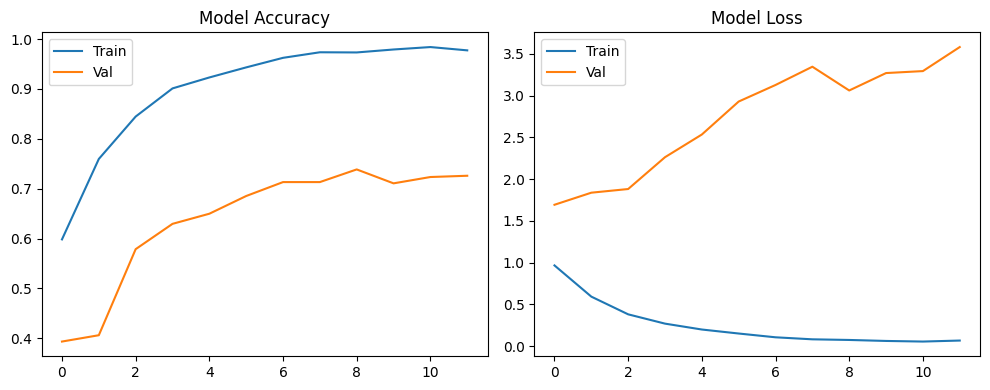

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Model Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Model Loss')
plt.legend()

plt.tight_layout()
plt.savefig('/kaggle/working/curves.png', dpi=300)
plt.show()

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 207ms/step
                  precision    recall  f1-score   support

    glioma_tumor     1.0000    0.1700    0.2906       100
meningioma_tumor     0.6933    0.9826    0.8129       115
        no_tumor     0.6624    0.9905    0.7939       105
 pituitary_tumor     0.9123    0.7027    0.7939        74

        accuracy                         0.7259       394
       macro avg     0.8170    0.7114    0.6728       394
    weighted avg     0.8040    0.7259    0.6717       394



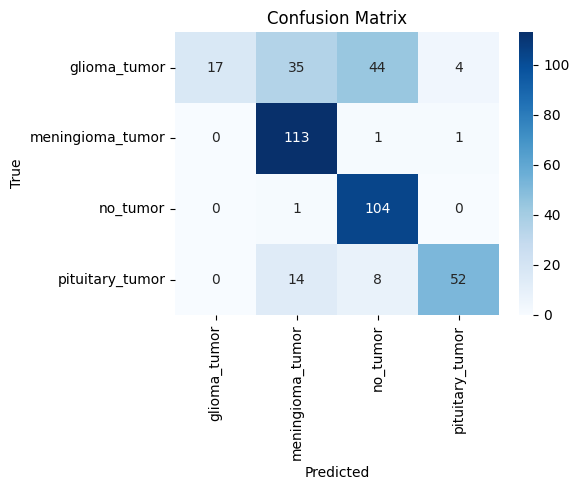

In [5]:
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix.png', dpi=300)
plt.show()